En este notebook se encuentran las pruebas realizads en colab para el primer analisis personal exploratorio de las variables

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
ruta = Path("../data/raw/movies_raw.csv")
df = pd.read_csv(ruta)
print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (17978, 16)


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
0,113727,Dark Seduction,2010-01-01,Released,0,0,89,Drama|Thriller|Romance,Lionsgate,Mexico,Español,es,6.799,102,1.6261,False
1,67250,12,2010-01-01,Released,0,0,3,Comedy,NaN,United States of America,English,en,5.000,57,0.3124,False
2,43615,"Lula, the Son of Brazil",2010-01-01,Released,9500000,3785593,130,Drama|History,LC Barreto|Filmes do Equador|InterVideo Produc...,Brazil,Português,pt,5.500,90,1.3337,False
3,38883,Protect and Serve,2010-01-03,Released,0,3807808,90,Comedy|Crime|Action,M6 Films|Same Player|Pathé|SCOPE Pictures|Webe...,France,Français,fr,4.500,106,0.5622,False
4,62105,Re-Cut,2010-01-04,Released,0,0,80,Horror|Thriller,Fritz Manger Productions|National Picture Show,United States of America,NaN,en,6.535,115,0.7341,False


In [14]:
df.info() #veamos el tipo de dato

<class 'pandas.DataFrame'>
RangeIndex: 17978 entries, 0 to 17977
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   movie_id              17978 non-null  int64  
 1   title                 17978 non-null  str    
 2   release_date          17978 non-null  str    
 3   status                17978 non-null  str    
 4   budget                17978 non-null  int64  
 5   revenue               17978 non-null  int64  
 6   runtime               17978 non-null  int64  
 7   genres                17968 non-null  str    
 8   production_companies  17484 non-null  str    
 9   production_countries  17802 non-null  str    
 10  spoken_languages      17886 non-null  str    
 11  original_language     17978 non-null  str    
 12  vote_average          17978 non-null  float64
 13  vote_count            17978 non-null  int64  
 14  popularity            17978 non-null  float64
 15  adult                 17978 no

In [15]:
columnas = [
    'movie_id', 'title', 'release_date', 'status', 'budget', 'revenue',
    'runtime', 'genres', 'production_companies', 'production_countries',
    'spoken_languages', 'original_language', 'vote_average', 'vote_count',
    'popularity', 'adult'
]

#ver cantidad de valores únicos, de columnas y los primeros 5 valores de cada columna para tener una idea como son 
for col in columnas:
    print(f"{col} ({df[col].nunique()} únicos):")
    print(df[col].unique()[:5])  # Muestra solo los primeros 5 para no saturar la pantalla
    print("-" * 40)

movie_id (17978 únicos):
[113727  67250  43615  38883  62105]
----------------------------------------
title (17322 únicos):
<StringArray>
[         'Dark Seduction',                      '12',
 'Lula, the Son of Brazil',       'Protect and Serve',
                  'Re-Cut']
Length: 5, dtype: str
----------------------------------------
release_date (4582 únicos):
<StringArray>
['2010-01-01', '2010-01-03', '2010-01-04', '2010-01-05', '2010-01-06']
Length: 5, dtype: str
----------------------------------------
status (1 únicos):
<StringArray>
['Released']
Length: 1, dtype: str
----------------------------------------
budget (1091 únicos):
[       0  9500000 20000000  2000000 19000000]
----------------------------------------
revenue (6443 únicos):
[       0  3785593  3807808 22039646 51417188]
----------------------------------------
runtime (217 únicos):
[ 89   3 130  90  80]
----------------------------------------
genres (2857 únicos):
<StringArray>
['Drama|Thriller|Romance',       

A simple vista Tenemos **adult**, **status** con 1 solo valor<br>
**Movie_id** como una identificador único<br>
**title** no tienen el total de películas puede ser que existan nombres repetidos de películas y no necesariamente sean las mismas<br>
**genres**  tiene multiples valores por columna probablemete se deba separar al igual que **production_companies** <br>
**release_date** se tiene que revisar el formato<br>
**runtime** se puede escalar?<br>
**production_countries** aparecen 1808 únicos existen 195 países en el mundo se debe revisar probablemente tenga múltiples valores como en genre<br>
**spoken_languages** tiene 1505 únicos existen spoken_languages hay que revisar si hay algunos múltiples igual <br>
**original_language** 80 únicos <br>
**vote_average** se puede escalar? revisar medianas etc...<br>
**vote_count**se puede escalar? revisar medianas etc...<br>
**popularity** se puede escalar? revisar medianas etc...<br>
**budget** (1091 únicos): se sigue revisando para ver si conviene usar la variable<br>
**revenue** (6443 únicos):se sigue revisando para ver si conviene usar la variable<br>

In [16]:
#checkeando renueve y budget viendo qla cantidad de valores nan y mayor a 0 que existen
df['revenue_valido'] = df['revenue'].notna() & (df['revenue'] > 0)
df['budget_valido'] = df['budget'].notna() & (df['budget'] > 0)
print("--- Info  'revenue' ---")
print(df['revenue_valido'].value_counts())
print("\n--- Info 'budget' ---")
print(df['budget_valido'].value_counts())


--- Info  'revenue' ---
revenue_valido
False    11156
True      6822
Name: count, dtype: int64

--- Info 'budget' ---
budget_valido
False    12463
True      5515
Name: count, dtype: int64


In [17]:
# Contar ceros hay en la columna budget y revenue
zeros_budget = (df['budget'] == 0).sum()
print(f"Cantidad de ceros en budget: {zeros_budget}")
zeros_revenue = (df['revenue'] == 0).sum()
print(f"Cantidad de ceros en revenue: {zeros_revenue}")

Cantidad de ceros en budget: 12463
Cantidad de ceros en revenue: 11156


Debemos evaluar si usamos renueve y budget para formulación de preguntas

In [18]:
#Checkeando si existen fechas invalidas
fechas = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

print("\nFechas inválidas:", fechas.isna().sum())

print("Fecha mínima:", fechas.min())
print("Fecha máxima:", fechas.max())


Fechas inválidas: 0
Fecha mínima: 2010-01-01 00:00:00
Fecha máxima: 2025-12-30 00:00:00


In [19]:
# 3. Estadísticas de variables numéricas
columnas = [
    'runtime',
    'vote_average',
    'vote_count',
    'popularity'
]

display(
    df[columnas].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    ).T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
runtime,17978.0,99.501224,25.045983,0.0000,7.0000,68.000000,90.0000,98.00000,110.000000,137.000000,165.000000,585.0000
vote_average,17978.0,6.329466,0.881686,1.8320,4.0000,4.800000,5.7860,6.38050,6.947000,7.700000,8.160460,9.9000
vote_count,17978.0,740.979086,2122.977234,50.0000,50.0000,54.000000,80.0000,152.00000,427.750000,3359.150000,10940.230000,40365.0000
popularity,17978.0,2.071475,3.075370,0.0079,0.2438,0.412885,0.7908,1.27975,2.161475,6.251085,14.578993,103.8592


In [20]:
display(
    df.loc[
        df['runtime'] > 180,
        ['title', 'release_date', 'runtime']
    ].sort_values('runtime', ascending=False)
)

# Las 10 películas con más votos
display(
    df.nlargest(
        10, 'vote_count'
    )[['title', 'release_date', 'vote_count', 'vote_average']]
)

# Las 10 películas con mayor popularidad
display(
    df.nlargest(
        10, 'popularity'
    )[['title', 'release_date', 'popularity']]
)

,title,release_date,runtime
2696,The Untold History Of The United States,2012-11-12,585
6873,O.J.: Made in America,2016-05-20,467
3536,Crystal Lake Memories: The Complete History of...,2013-09-13,400
417,Carlos,2010-07-07,339
716,The Big Four: Live in Sofia,2010-10-29,319
6344,Happy Hour,2015-12-12,317
11000,In Search of Darkness,2019-05-01,264
15656,Trenque Lauquen,2023-05-02,260
8573,Wormwood,2017-09-01,256
1090,Kill Bill: The Whole Bloody Affair,2011-03-27,254


,title,release_date,vote_count,vote_average
4983,Interstellar,2014-11-05,40365,8.482
434,Inception,2010-07-15,39595,8.373
2115,The Avengers,2012-04-25,38814,8.057
6531,Deadpool,2016-02-09,32930,7.624
9534,Avengers: Infinity War,2018-04-25,32319,8.239
4568,Guardians of the Galaxy,2014-07-30,29914,7.907
2814,Django Unchained,2012-12-25,28230,8.192
10977,Avengers: Endgame,2019-04-24,28060,8.239
11536,Joker,2019-10-01,27930,8.123
3916,The Wolf of Wall Street,2013-12-25,26127,8.027


,title,release_date,popularity
17963,Avatar: Fire and Ash,2025-12-17,103.8592
17649,Demon Slayer: Kimetsu no Yaiba Infinity Castle,2025-07-18,90.0874
15949,Graphic Desires,2023-08-31,74.6626
4983,Interstellar,2014-11-05,59.4383
14085,Spider-Man: No Way Home,2021-12-15,55.7341
17696,The Shadow's Edge,2025-08-16,51.8726
17666,War of the Worlds,2025-07-29,50.1836
17965,The Housemaid,2025-12-18,46.5816
17601,Jurassic World Rebirth,2025-06-23,44.4832
17167,Moana 2,2024-11-21,44.4430


In [21]:
df['release_date'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

df['release_year'] = df['release_date'].dt.year

peliculas_por_anio = (
    df.groupby('release_year')['movie_id']
    .nunique()
    .sort_index()
)

print(peliculas_por_anio)

release_year
2010     892
2011     958
2012     976
2013    1108
2014    1210
2015    1258
2016    1315
2017    1398
2018    1426
2019    1396
2020    1077
2021    1125
2022    1151
2023    1071
2024     901
2025     716
Name: movie_id, dtype: int64


Ahora hay que ver genres

In [22]:
unique_genres = df['genres'].dropna().str.split('|').explode().unique()
print("Generos : ",unique_genres)

Generos :  <StringArray>
[          'Drama',        'Thriller',         'Romance',          'Comedy',
         'History',           'Crime',          'Action',          'Horror',
         'Fantasy', 'Science Fiction',         'Mystery',       'Adventure',
          'Family',             'War',        'TV Movie',       'Animation',
     'Documentary',           'Music',         'Western']
Length: 19, dtype: str


In [23]:
unique_genres = df['production_countries'].dropna().str.split('|').explode().unique()
print(unique_genres)

<StringArray>
[                  'Mexico', 'United States of America',
                   'Brazil',                   'France',
                    'Italy',                   'Serbia',
                'Australia',                   'Canada',
              'South Korea',           'United Kingdom',
 ...
                 'Honduras',               'Costa Rica',
                   'Kosovo',         'French Polynesia',
     'Netherlands Antilles',               'Madagascar',
      'St. Kitts and Nevis',            'Liechtenstein',
               'Mauritania',                   'Kuwait']
Length: 137, dtype: str


In [24]:
frecuencia_generos = (
    df['genres']
    .dropna()
    .str.split('|')
    .explode()
    .value_counts()
)

print(frecuencia_generos)

genres
Drama              7767
Comedy             6002
Thriller           4183
Action             3284
Horror             2734
Romance            2573
Crime              2024
Adventure          1763
Science Fiction    1575
Family             1511
Animation          1478
Fantasy            1467
Mystery            1371
Documentary        1103
History             884
TV Movie            882
Music               591
War                 467
Western             138
Name: count, dtype: int64


Resultados
**title** no tienen el total de películas puede ser que existan nombres repetidos de películas y no necesariamente sean las mismas<br>
**genres**  tiene multiples valores por columna probablemete se deba separar al igual que **production_companies** <br>
**release_date** se tiene que revisar el formato<br>
**runtime** se puede escalar?<br>
**production_countries** aparecen 1808 únicos existen 195 países en el mundo se debe revisar probablemente tenga múltiples valores como en genre<br>
**spoken_languages** tiene 1505 únicos existen spoken_languages hay que revisar si hay algunos múltiples igual <br>
**original_language** 80 únicos <br>
**vote_average** se puede escalar? revisar medianas etc...<br>
**vote_count**se puede escalar? revisar medianas etc...<br>
**popularity** se puede escalar? revisar medianas etc...<br>
**budget** (1091 únicos): se sigue revisando para ver si conviene usar la variable<br>
**revenue** (6443 únicos):se sigue revisando para ver si conviene usar la variable<br>

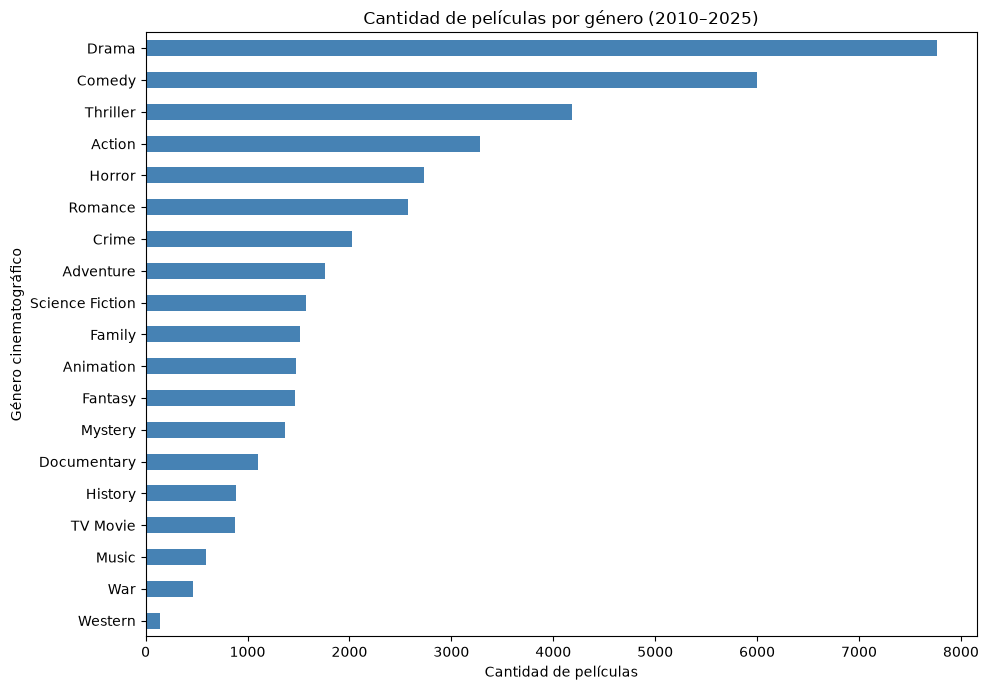

In [25]:
frecuencia_generos.sort_values().plot(
    kind='barh',
    figsize=(10, 7),
    color='steelblue'
)

plt.title('Cantidad de películas por género (2010–2025)')
plt.xlabel('Cantidad de películas')
plt.ylabel('Género cinematográfico')
plt.tight_layout()
plt.show()

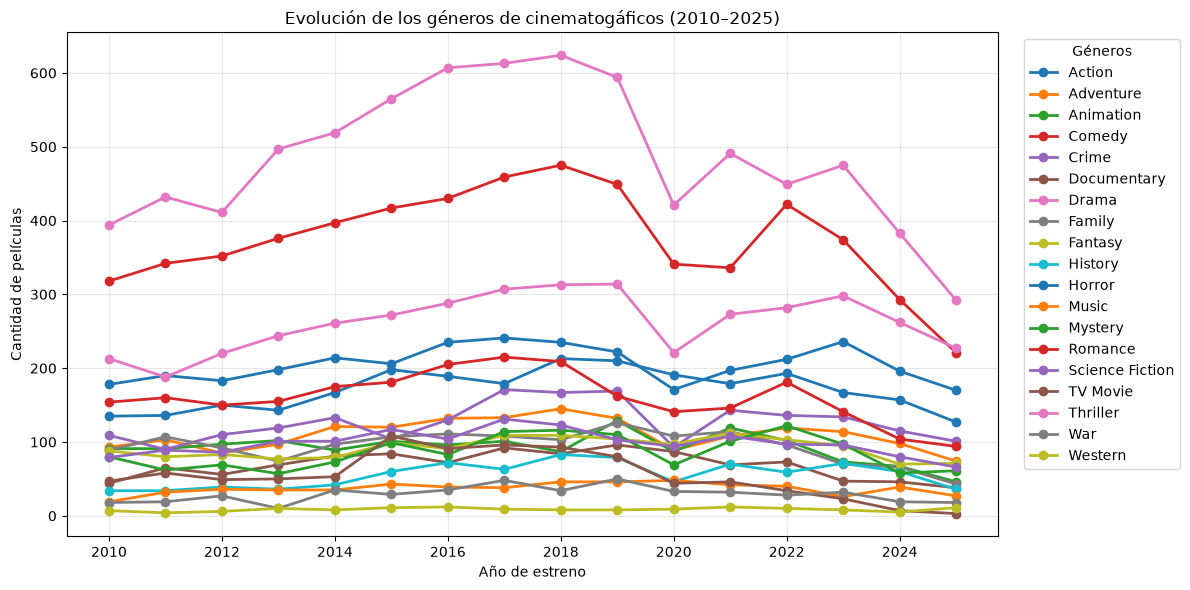

In [26]:
df_g = df.copy()
df_g['year'] = pd.to_datetime(
    df_g['release_date'], errors='coerce'
).dt.year

df_g['genres'] = df_g['genres'].str.split('|')
df_g = df_g.explode('genres')
df_g['genres'] = df_g['genres'].str.strip()

df_g = df_g[
    df_g['year'].between(2010, 2025)
    & df_g['genres'].notna()
    & df_g['genres'].ne('')
]
todos_generos = df_g['genres'].value_counts().index
#top10 = df_g['genres'].value_counts().head(10).index

evolucion = (
    df_g[df_g['genres'].isin(todos_generos)]
    .groupby(['year', 'genres'])['movie_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(range(2010, 2026), fill_value=0)
)
ax = evolucion.plot(
    kind='line',
    marker='o',
    figsize=(12, 6),
    linewidth=2
)
ax.set_title('Evolución de los géneros de cinematogáficos (2010–2025)')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Cantidad de películas')
ax.legend(
    title='Géneros',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

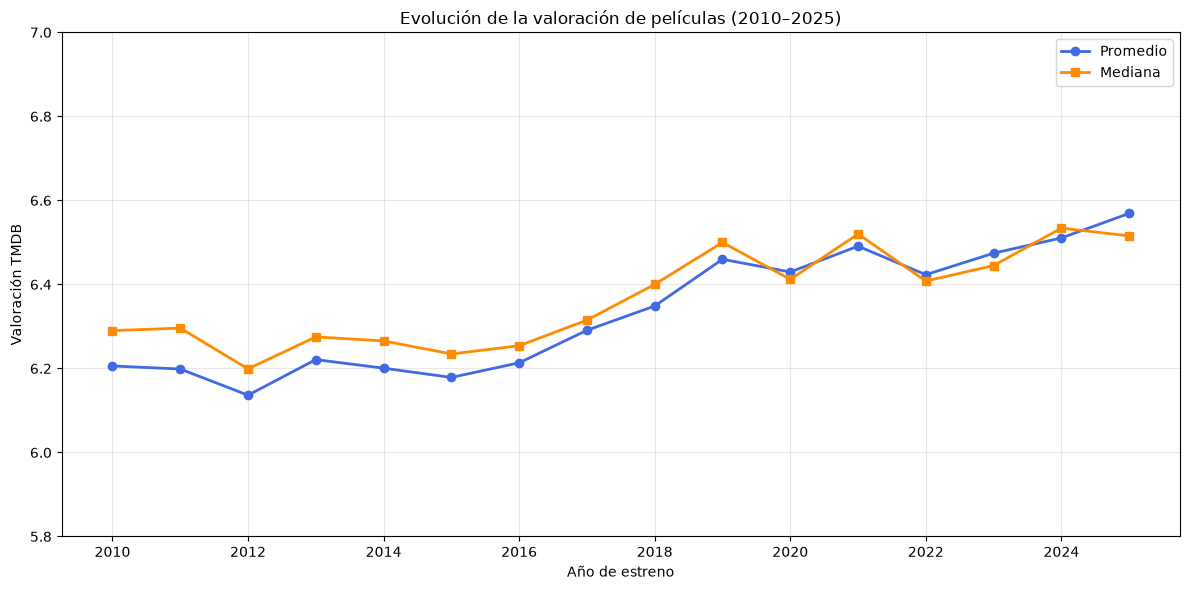

In [27]:
df_v = df.copy()
df_v['year'] = pd.to_datetime(
    df_v['release_date'], errors='coerce'
).dt.year
df_v = df_v[
    df_v['year'].between(2010, 2025)
    & df_v['vote_average'].notna()
]
valoracion_anual = (
    df_v.groupby('year')['vote_average']
    .agg(
        promedio='mean',
        mediana='median'
    )
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    valoracion_anual.index,
    valoracion_anual['promedio'],
    marker='o',
    linewidth=2,
    color='royalblue',
    label='Promedio'
)

ax.plot(
    valoracion_anual.index,
    valoracion_anual['mediana'],
    marker='s',
    linewidth=2,
    color='darkorange',
    label='Mediana'
)

ax.set_title('Evolución de la valoración de películas (2010–2025)')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Valoración TMDB')
ax.set_ylim(5.8, 7.0)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

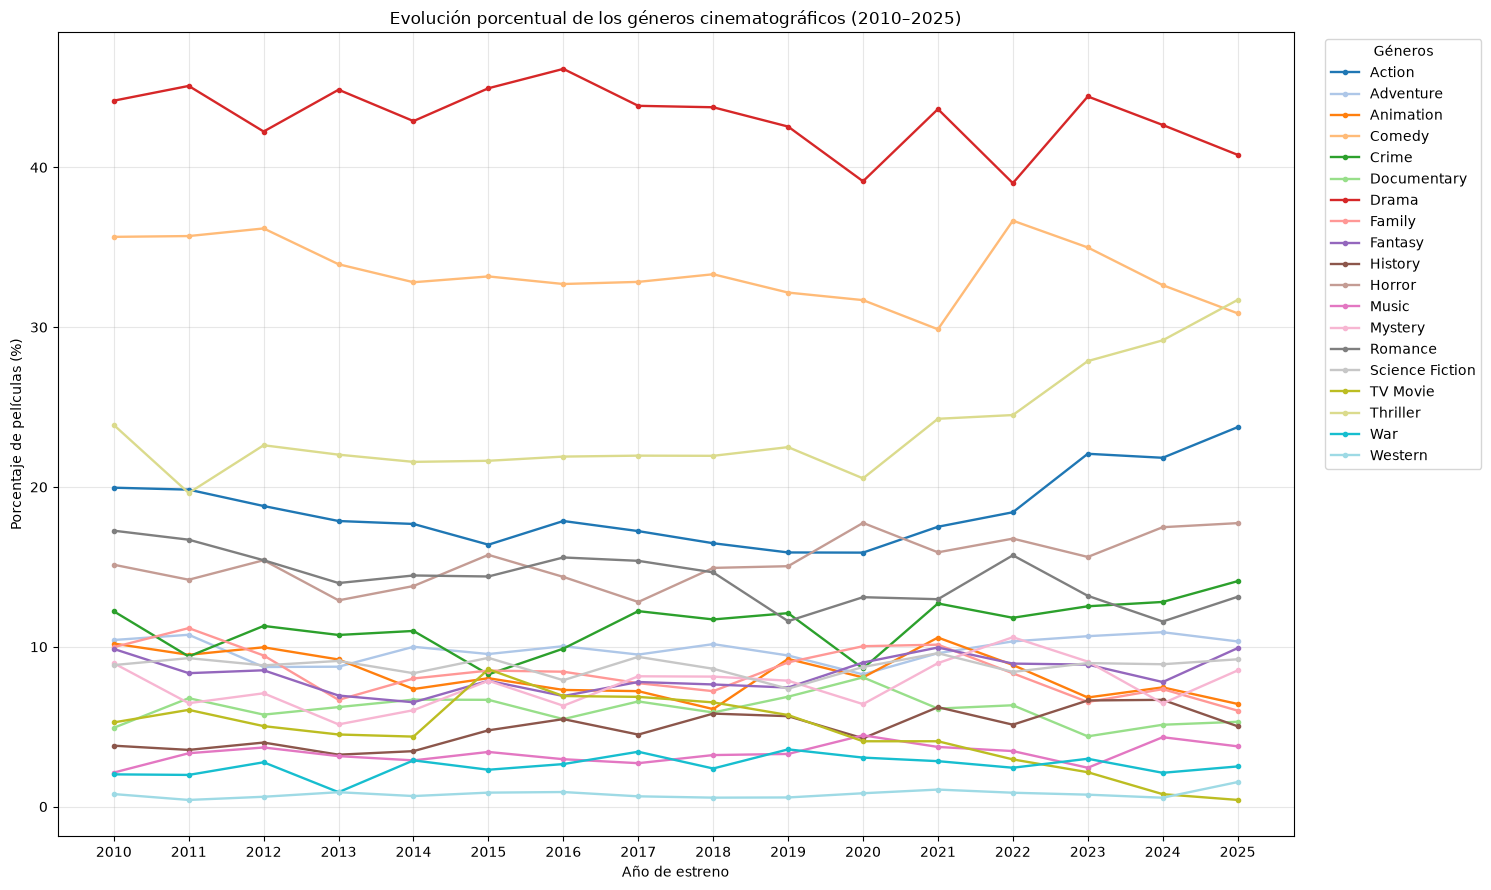

In [28]:
total_anual = (
    df_g.groupby('year')['movie_id']
    .nunique()
    .reindex(range(2010, 2026))
)
generos_anuales = (
    df_g.groupby(['year', 'genres'])['movie_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(range(2010, 2026), fill_value=0)
)
generos_porcentaje = (
    generos_anuales
    .div(total_anual.replace(0, float('nan')), axis=0)
    * 100
)
ax = generos_porcentaje.plot(
    kind='line',
    figsize=(15, 9),
    linewidth=1.7,
    marker='o',
    markersize=3,
    colormap='tab20'
)
ax.set_title(
    'Evolución porcentual de los géneros cinematográficos (2010–2025)'
)
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Porcentaje de películas (%)')
ax.set_xticks(range(2010, 2026))

ax.legend(
    title='Géneros',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Evolución porcentual de los géneros cinematográficos (2010–2025)
Entre 2010 y 2025, Drama y Comedy mantuvieron una presencia predominante entre las películas analizadas. Sin embargo, se observan cambios en la composición relativa de los géneros cinematográficos, destacando un aumento de la participación de Action y Thriller, mientras que Drama y Comedy presentan disminuciones moderadas. Estos resultados sugieren una transformación en la distribución de géneros dentro del conjunto de películas registradas en TMDB.

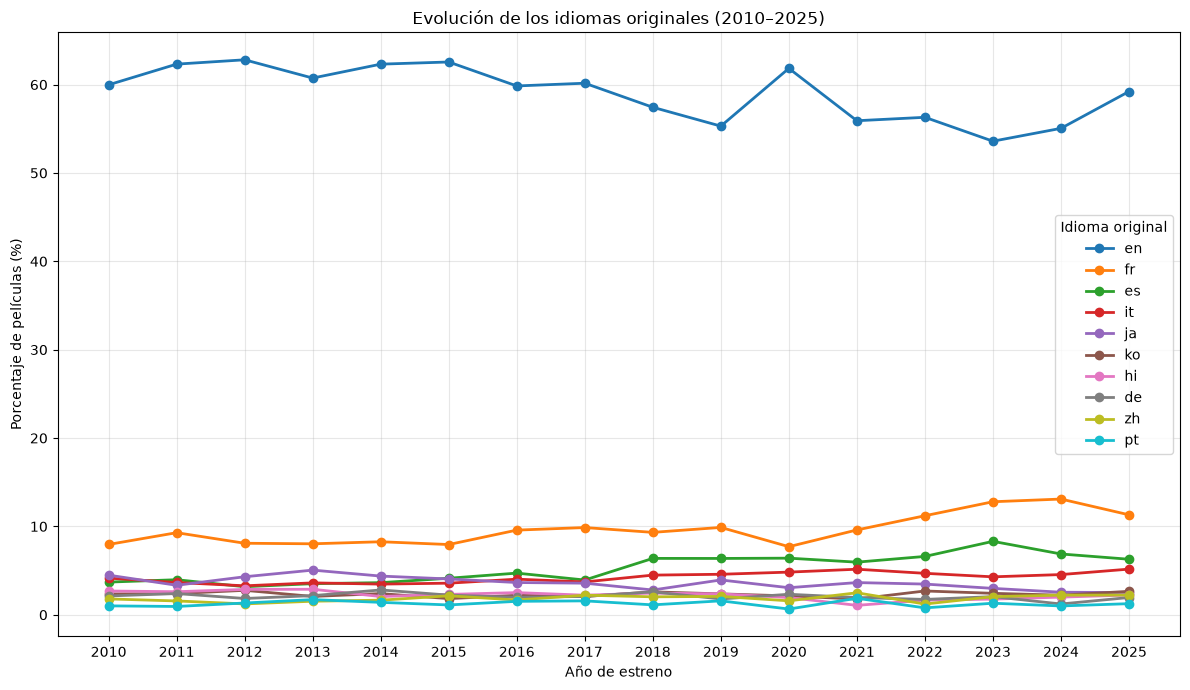

In [29]:
df_i = df.copy()

df_i['year'] = pd.to_datetime(
    df_i['release_date'], errors='coerce'
).dt.year
df_i = df_i[
    df_i['year'].between(2010, 2025)
    & df_i['original_language'].notna()
]
top_idiomas = (
    df_i['original_language']
    .value_counts()
    .head(10)
    .index
)
idiomas_anuales = pd.crosstab(
    df_i['year'],
    df_i['original_language'],
    normalize='index'
) * 100
idiomas_anuales = idiomas_anuales[
    top_idiomas
].reindex(range(2010, 2026))

ax = idiomas_anuales.plot(
    figsize=(12, 7),
    marker='o',
    linewidth=2,
    colormap='tab10'
)
ax.set_title('Evolución de los idiomas originales (2010–2025)')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Porcentaje de películas (%)')
ax.set_xticks(range(2010, 2026))
ax.legend(title='Idioma original')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Evolución de los idiomas originales (2010–2025)


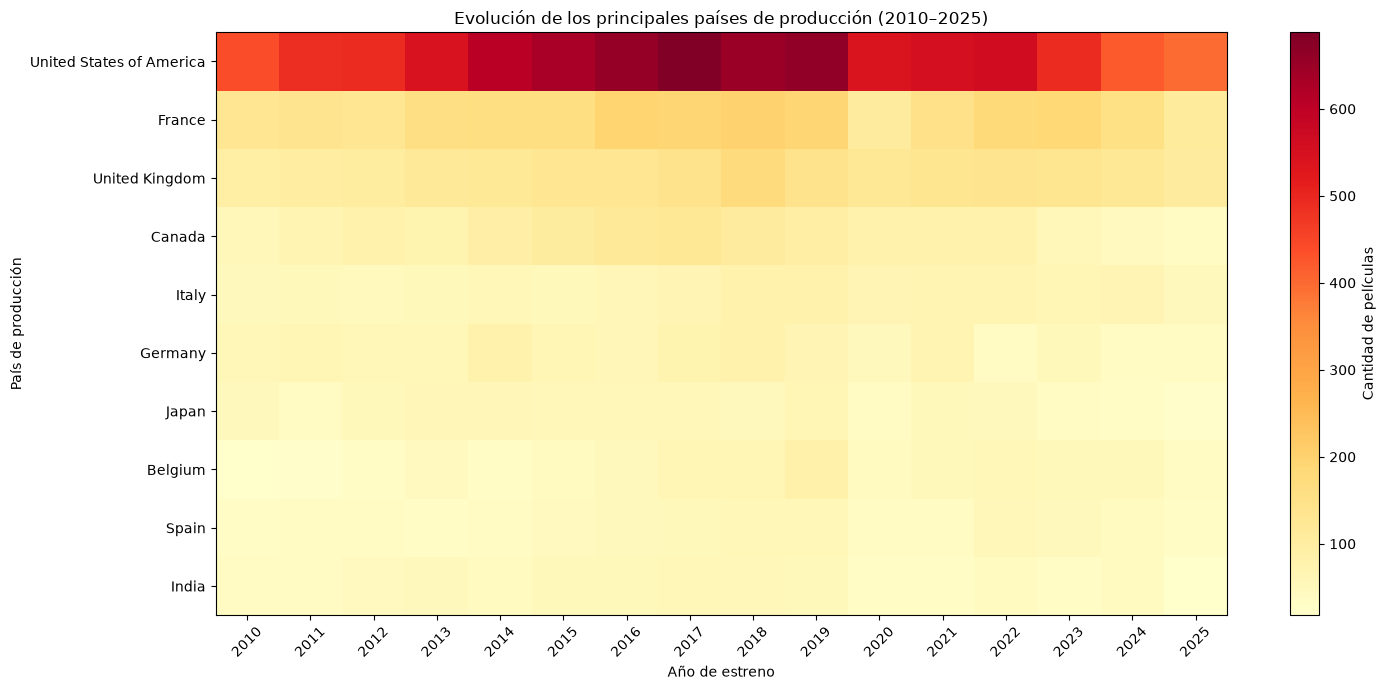

In [30]:
df_p = df.copy()

df_p['year'] = pd.to_datetime(
    df_p['release_date'], errors='coerce'
).dt.year

# Separar países
df_p['production_countries'] = (
    df_p['production_countries'].str.split('|')
)

df_p = df_p.explode('production_countries')

df_p['production_countries'] = (
    df_p['production_countries'].str.strip()
)

# Filtrar registros válidos
df_p = df_p[
    df_p['year'].between(2010, 2025)
    & df_p['production_countries'].notna()
    & df_p['production_countries'].ne('')
]

# Identificar los 10 países más frecuentes
top_paises = (
    df_p.groupby('production_countries')['movie_id']
    .nunique()
    .nlargest(10)
    .index
)

# Cantidad de películas por país y año
paises_anuales = (
    df_p[df_p['production_countries'].isin(top_paises)]
    .groupby(['production_countries', 'year'])['movie_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=top_paises,
        columns=range(2010, 2026),
        fill_value=0
    )
)

# Crear mapa de calor
fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(
    paises_anuales.values,
    cmap='YlOrRd',
    aspect='auto'
)

ax.set_xticks(np.arange(len(paises_anuales.columns)))
ax.set_xticklabels(paises_anuales.columns, rotation=45)

ax.set_yticks(np.arange(len(paises_anuales.index)))
ax.set_yticklabels(paises_anuales.index)

ax.set_title('Evolución de los principales países de producción (2010–2025)')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('País de producción')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Cantidad de películas')

plt.tight_layout()
plt.show()

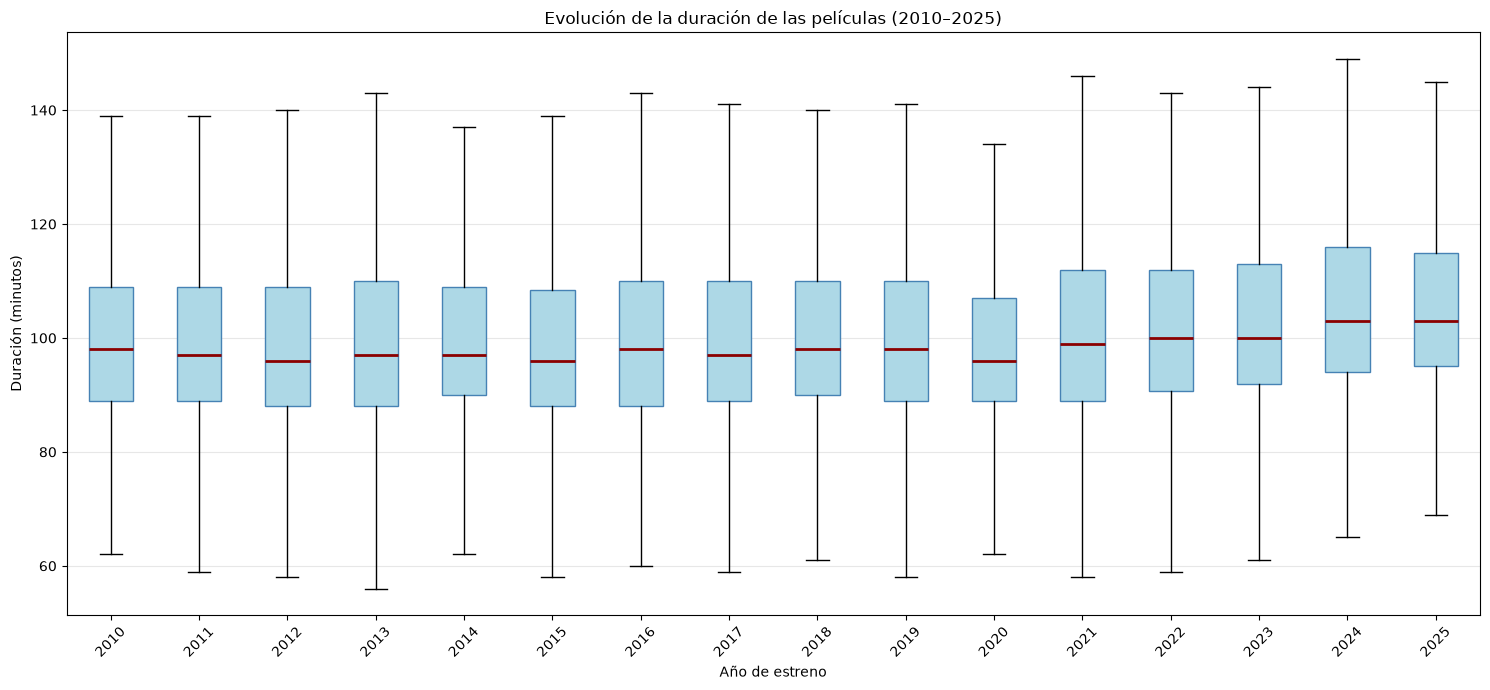

In [31]:
df_duracion = df.copy()

df_duracion['year'] = pd.to_datetime(
    df_duracion['release_date'],
    errors='coerce'
).dt.year

df_duracion = df_duracion[
    df_duracion['year'].between(2010, 2025)
    & df_duracion['runtime'].notna()
    & (df_duracion['runtime'] > 0)
]

anios = list(range(2010, 2026))

duraciones = [
    df_duracion.loc[
        df_duracion['year'] == anio, 'runtime'
    ].values
    for anio in anios
]

fig, ax = plt.subplots(figsize=(15, 7))

ax.boxplot(
    duraciones,
    tick_labels=anios,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', edgecolor='steelblue'),
    medianprops=dict(color='darkred', linewidth=2)
)

ax.set_title(
    'Evolución de la duración de las películas (2010–2025)'
)
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Duración (minutos)')

ax.grid(axis='y', alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
resumen_duracion = (
    df_duracion
    .groupby('year')['runtime']
    .agg(
        peliculas='count',
        promedio='mean',
        mediana='median',
        minimo='min',
        maximo='max'
    )
    .round(2)
)

display(resumen_duracion)

,peliculas,promedio,mediana,minimo,maximo
year,,,,,
2010,890,98.41,98.0,2,339
2011,958,97.27,97.0,3,254
2012,974,98.87,96.0,2,585
2013,1105,98.37,97.0,2,400
2014,1209,98.92,97.0,2,250
2015,1255,97.71,96.0,4,317
2016,1315,99.64,98.0,2,467
2017,1398,98.41,97.0,2,256
2018,1421,100.35,98.0,4,230


### Análisis de la evolución de la duración cinematográfica (2010–2025)

El análisis de las películas registradas en TMDB evidencia que la duración mediana se mantuvo relativamente estable entre 2010 y 2019, fluctuando entre 96 y 98 minutos. En 2020 se registró una mediana de 96 minutos, mientras que desde 2021 se observa un incremento progresivo, alcanzando 103 minutos en 2024 y 2025.

Al comparar los extremos del período, la duración mediana aumentó 5 minutos, mientras que el promedio pasó de 98,41 a 105,99 minutos, equivalente a un incremento de 7,58 minutos.

Estos resultados sugieren una tendencia reciente hacia películas de mayor duración dentro del conjunto analizado. No obstante, la presencia de producciones de muy corta duración y posibles diferencias en la cobertura anual del dataset hacen necesario interpretar esta tendencia con cautela.

==> existen filmes con 2, 3 minutos tambíen 430 al ver l 

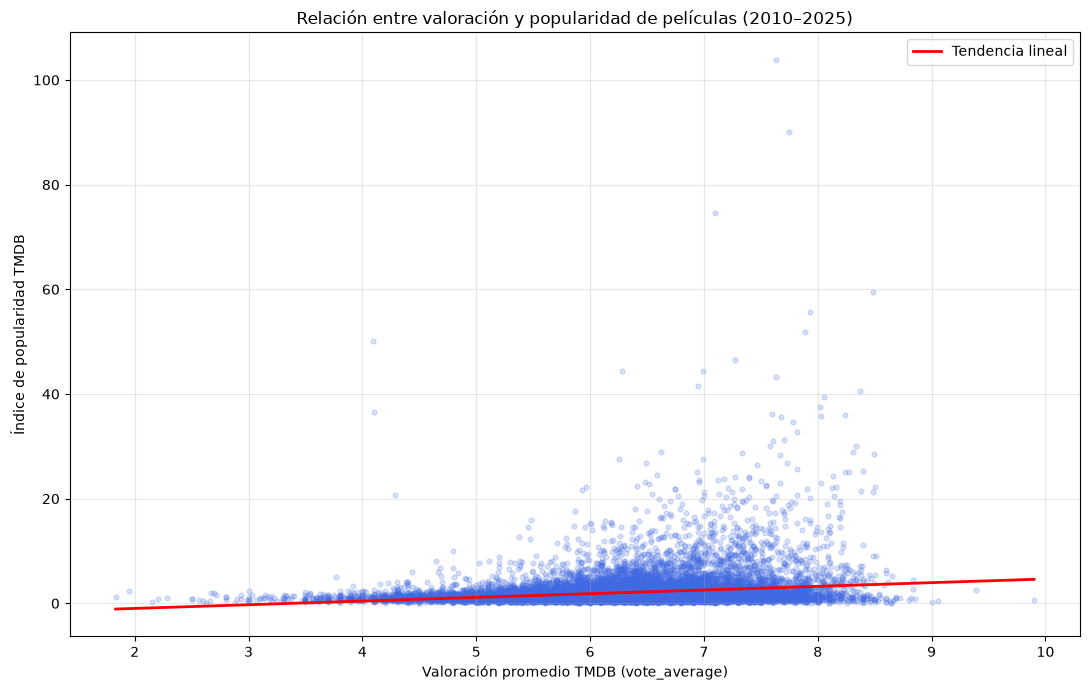

Correlación de Pearson: 0.202
Correlación de Spearman: 0.196


In [35]:
df_corr = df[
    ['vote_average', 'popularity']
].dropna().copy()

pearson = df_corr['vote_average'].corr(
    df_corr['popularity'], method='pearson'
)

spearman = df_corr['vote_average'].corr(
    df_corr['popularity'], method='spearman'
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    df_corr['vote_average'],
    df_corr['popularity'],
    alpha=0.20,
    s=12,
    color='royalblue'
)

m, b = np.polyfit(
    df_corr['vote_average'],
    df_corr['popularity'],
    1
)

x = np.linspace(
    df_corr['vote_average'].min(),
    df_corr['vote_average'].max(),
    100
)

ax.plot(
    x, m*x + b,
    color='red',
    linewidth=2,
    label='Tendencia lineal'
)

ax.set_title(
    'Relación entre valoración y popularidad de películas (2010–2025)'
)
ax.set_xlabel('Valoración promedio TMDB (vote_average)')
ax.set_ylabel('Índice de popularidad TMDB')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Correlación de Pearson: {pearson:.3f}')
print(f'Correlación de Spearman: {spearman:.3f}')

### Relación entre valoración y popularidad de las películas

El análisis de correlación entre la valoración promedio (`vote_average`) y el índice de popularidad (`popularity`) de las películas registradas en TMDB presenta coeficientes de Pearson de 0,202 y Spearman de 0,196.

Ambos resultados evidencian una asociación positiva débil, lo que sugiere que las películas con mejores valoraciones tienden a presentar una popularidad ligeramente superior. Sin embargo, la dispersión de los datos demuestra que una valoración elevada no necesariamente se corresponde con una popularidad alta.

En consecuencia, la valoración y la popularidad deben considerarse indicadores diferentes de la recepción cinematográfica. Asimismo, estos resultados describen una asociación estadística y no permiten establecer relaciones causales.

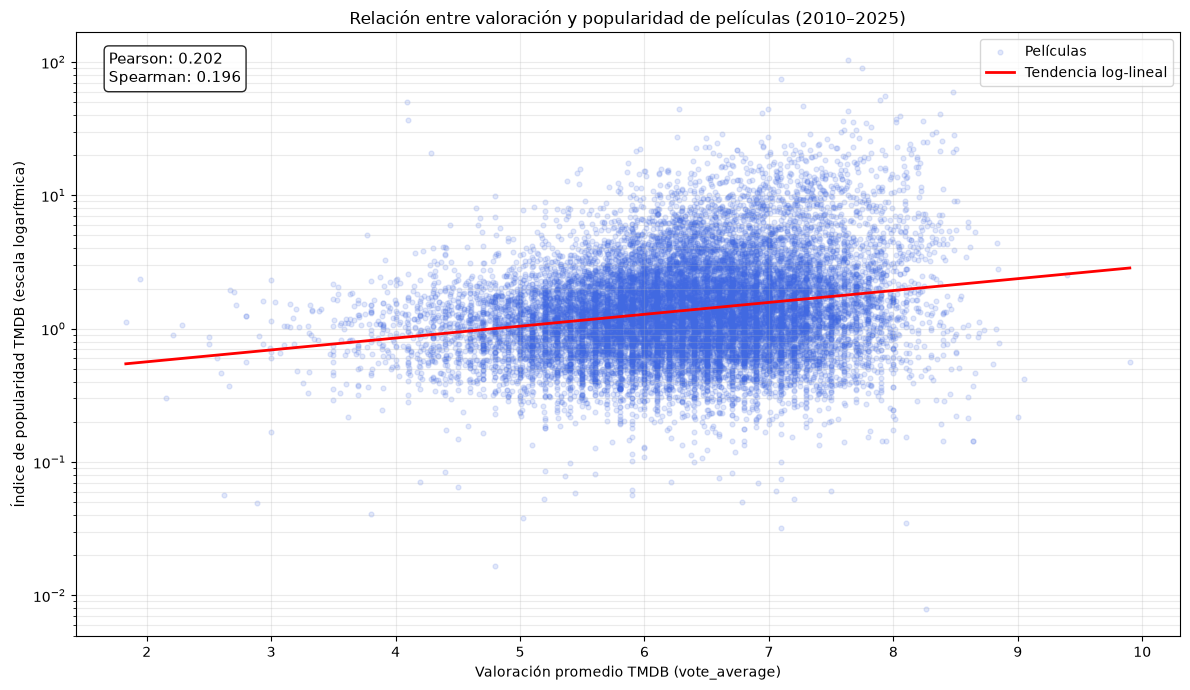

Películas analizadas: 17,978
Correlación de Pearson: 0.202
Correlación de Spearman: 0.196


In [36]:
df_corr = df[
    ['vote_average', 'popularity']
].dropna().copy()
df_corr = df_corr[
    (df_corr['popularity'] > 0) &
    (df_corr['vote_average'] > 0)
]
pearson = df_corr['vote_average'].corr(
    df_corr['popularity']
)
spearman = (
    df_corr['vote_average'].rank()
    .corr(df_corr['popularity'].rank())
)
x_datos = df_corr['vote_average'].to_numpy()
y_datos = df_corr['popularity'].to_numpy()
m, b = np.polyfit(
    x_datos,
    np.log10(y_datos),
    1
)
x_linea = np.linspace(
    x_datos.min(),
    x_datos.max(),
    100
)
y_linea = 10 ** (m * x_linea + b)

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    x_datos,
    y_datos,
    alpha=0.15,
    s=12,
    color='royalblue',
    label='Películas'
)

ax.plot(
    x_linea,
    y_linea,
    color='red',
    linewidth=2,
    label='Tendencia log-lineal'
)

ax.set_yscale('log')
ax.set_title(
    'Relación entre valoración y popularidad de películas (2010–2025)'
)
ax.set_xlabel('Valoración promedio TMDB (vote_average)')
ax.set_ylabel('Índice de popularidad TMDB (escala logarítmica)')

texto = (
    f'Pearson: {pearson:.3f}\n'
    f'Spearman: {spearman:.3f}'
)

ax.text(
    0.03, 0.97,
    texto,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.85
    )
)
ax.legend(loc='upper right')
ax.grid(alpha=0.25, which='both')

plt.tight_layout()
plt.show()

# 5. Mostrar resultados
print(f'Películas analizadas: {len(df_corr):,}')
print(f'Correlación de Pearson: {pearson:.3f}')
print(f'Correlación de Spearman: {spearman:.3f}')

### Relación entre valoración y popularidad cinematográfica (2010–2025)

El análisis de 17.978 películas registradas en TMDB muestra una correlación positiva débil entre la valoración promedio y el índice de popularidad, con coeficientes de Pearson de 0,202 y Spearman de 0,196.

La visualización mediante un gráfico de dispersión con escala logarítmica permite observar una amplia variabilidad en los niveles de popularidad para películas con valoraciones similares. Aunque existe una ligera tendencia positiva, una mayor valoración no implica necesariamente una mayor popularidad.

Estos resultados indican que la valoración y la popularidad representan dimensiones diferentes de la recepción cinematográfica. La asociación observada no permite establecer causalidad y debe interpretarse dentro de las características y limitaciones del conjunto de datos analizado.